# Q1 – Load the TinyStories Dataset

```
# This is formatted as code
```



In [1]:
# Install the Hugging Face datasets library
!pip install datasets

In [2]:
# Import the function used to load datasets
from datasets import load_dataset

In [3]:
# Load the TinyStories dataset from Hugging Face
dataset = load_dataset("roneneldan/TinyStories")

# Display the dataset information
print(dataset)

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})


In [4]:
# Get the first story from the training dataset
first_story = dataset["train"][0]["text"]

# Display the story
print(first_story)

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.


In [5]:
# Display the first 5 stories
for i in range(5):

    # Get the story text
    story = dataset["train"][i]["text"]

    # Display the story number
    print("Story", i + 1)

    # Display the story
    print(story)

    # Print a separator between stories
    print("-" * 60)

Story 1
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
------------------------------------------------------------
Story 2
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in t

In [6]:
# Check the length of the first 5 stories
for i in range(5):

    # Get the story text
    story = dataset["train"][i]["text"]

    # Calculate the number of characters
    length = len(story)

    # Display the story length
    print("Story", i + 1, "Length:", length)

Story 1 Length: 701
Story 2 Length: 705
Story 3 Length: 822
Story 4 Length: 845
Story 5 Length: 638


In [7]:
# Display the available columns in the dataset
print(dataset["train"].column_names)

# Display the number of training stories
print("Number of training stories:", len(dataset["train"]))

# Display the number of validation stories
print("Number of validation stories:", len(dataset["validation"]))

['text']
Number of training stories: 2119719
Number of validation stories: 21990


## Q2 – Preprocess the Text

In [11]:
# Select a small subset of stories for training
# Using a small subset makes the model faster to train
small_dataset = dataset["train"].select(range(5000))

# Display the number of selected stories
print("Number of selected stories:", len(small_dataset))

Number of selected stories: 5000


In [12]:
# Combine all stories into one text
text = "\n".join(small_dataset["text"])

# Get all unique characters
chars = sorted(list(set(text)))

# Display the number of unique characters
print("Number of unique characters:", len(chars))

# Display the characters
print(chars)

Number of unique characters: 90
['\n', ' ', '!', '"', '$', "'", ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '¡', '¦', '©', '«', '±', '³', '»', 'Â', 'Ã', 'â', 'œ', '˜', '“', '”', '€', '™']


In [13]:
# Create a dictionary to convert characters into numbers
char_to_int = {ch: i for i, ch in enumerate(chars)}

# Create a dictionary to convert numbers back into characters
int_to_char = {i: ch for i, ch in enumerate(chars)}

# Display a few character mappings
print("Character to number:", list(char_to_int.items())[:10])

Character to number: [('\n', 0), (' ', 1), ('!', 2), ('"', 3), ('$', 4), ("'", 5), (',', 6), ('-', 7), ('.', 8), ('0', 9)]


In [14]:
# Select the first story
sample_story = small_dataset[0]["text"]

# Convert each character into its corresponding number
encoded_story = [char_to_int[ch] for ch in sample_story]

# Display the original story
print("Original Story:")
print(sample_story)

# Display the tokenized story
print("\nTokenized Story:")
print(encoded_story[:100])

Original Story:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

Tokenized Story:
[36, 61, 52, 1, 51, 48, 72, 6, 1, 48, 1, 59, 56, 67, 67, 59, 52, 1, 54, 56, 65, 59, 1, 61, 48, 60, 52, 51, 1, 33, 56, 59, 72, 1, 53, 62, 68, 61, 51, 1, 48, 1, 61, 52, 52, 51, 59, 52, 1, 56, 61, 1, 55, 52, 65, 1, 65, 62, 62, 60, 8, 1, 40, 55, 52, 1, 58, 61, 52, 70,

## Q3 – Preparing Training Data

In [15]:
# Convert the complete text into numerical tokens
encoded_text = [char_to_int[ch] for ch in text]

# Display the total number of tokens
print("Total number of tokens:", len(encoded_text))

Total number of tokens: 4181739


In [16]:
# Define the length of each input sequence
sequence_length = 64

# Display the sequence length
print("Sequence length:", sequence_length)

Sequence length: 64


In [17]:
# Create empty lists to store input and target sequences
X = []
y = []

# Create sequences for next-character prediction
for i in range(len(encoded_text) - sequence_length):

    # Input sequence
    input_sequence = encoded_text[i:i + sequence_length]

    # Target sequence is shifted by one character
    target_sequence = encoded_text[i + 1:i + sequence_length + 1]

    # Add the sequences to the lists
    X.append(input_sequence)
    y.append(target_sequence)

# Display the number of sequences
print("Number of input sequences:", len(X))

Number of input sequences: 4181675


In [18]:
# Import PyTorch
import torch

# Convert input sequences into a tensor
X = torch.tensor(X, dtype=torch.long)

# Convert target sequences into a tensor
y = torch.tensor(y, dtype=torch.long)

# Display the shapes
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([4181675, 64])
Target shape: torch.Size([4181675, 64])


In [19]:
# Display the first input sequence
print("Input sequence:")
print(X[0])

# Display the corresponding target sequence
print("\nTarget sequence:")
print(y[0])

Input sequence:
tensor([36, 61, 52,  1, 51, 48, 72,  6,  1, 48,  1, 59, 56, 67, 67, 59, 52,  1,
        54, 56, 65, 59,  1, 61, 48, 60, 52, 51,  1, 33, 56, 59, 72,  1, 53, 62,
        68, 61, 51,  1, 48,  1, 61, 52, 52, 51, 59, 52,  1, 56, 61,  1, 55, 52,
        65,  1, 65, 62, 62, 60,  8,  1, 40, 55])

Target sequence:
tensor([61, 52,  1, 51, 48, 72,  6,  1, 48,  1, 59, 56, 67, 67, 59, 52,  1, 54,
        56, 65, 59,  1, 61, 48, 60, 52, 51,  1, 33, 56, 59, 72,  1, 53, 62, 68,
        61, 51,  1, 48,  1, 61, 52, 52, 51, 59, 52,  1, 56, 61,  1, 55, 52, 65,
         1, 65, 62, 62, 60,  8,  1, 40, 55, 52])


## Q4 – Build the Transformer Architecture

In [20]:
# Import PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

In [21]:
# Define the Tiny Transformer Language Model
class TinyTransformer(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128, num_heads=4,
                 num_layers=2, sequence_length=64):

        # Initialize the parent class
        super().__init__()

        # Store the sequence length
        self.sequence_length = sequence_length

        # Token embedding converts token numbers into vectors
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)

        # Positional embedding gives information about token positions
        self.position_embedding = nn.Embedding(
            sequence_length, embedding_dim
        )

        # Create one Transformer encoder layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=4 * embedding_dim,
            batch_first=True
        )

        # Create multiple Transformer layers
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Layer normalization
        self.layer_norm = nn.LayerNorm(embedding_dim)

        # Convert the Transformer output into vocabulary predictions
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):

        # Get the batch size and sequence length
        batch_size, seq_len = x.shape

        # Create position numbers
        positions = torch.arange(
            seq_len,
            device=x.device
        )

        # Get token embeddings
        token_emb = self.token_embedding(x)

        # Get positional embeddings
        position_emb = self.position_embedding(positions)

        # Add token and positional embeddings
        x = token_emb + position_emb

        # Create a causal mask
        # This prevents the model from seeing future tokens
        mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device),
            diagonal=1
        ).bool()

        # Pass data through the Transformer
        x = self.transformer(x, mask=mask)

        # Apply layer normalization
        x = self.layer_norm(x)

        # Generate vocabulary predictions
        logits = self.output_layer(x)

        return logits

In [22]:
# Get the number of unique characters
vocab_size = len(chars)

# Display the vocabulary size
print("Vocabulary size:", vocab_size)

Vocabulary size: 90


In [23]:
# Create the Tiny Transformer model
model = TinyTransformer(
    vocab_size=vocab_size,
    embedding_dim=128,
    num_heads=4,
    num_layers=2,
    sequence_length=sequence_length
)

# Display the model architecture
print(model)

TinyTransformer(
  (token_embedding): Embedding(90, 128)
  (position_embedding): Embedding(64, 128)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (output_layer): Linear(in_features=128, out_features=90, bias=True)
)


In [24]:
# Take a small batch of input sequences
sample_input = X[:2]

# Pass the input through the model
sample_output = model(sample_input)

# Display the output shape
print("Output shape:", sample_output.shape)

Output shape: torch.Size([2, 64, 90])


## Q5 – Initialize the Model

In [25]:
# Check whether a GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Display the device being used
print("Using device:", device)

Using device: cpu


In [26]:
# Move the Transformer model to the selected device
model = model.to(device)

# Display the model device
print("Model is ready on:", device)

Model is ready on: cpu


In [27]:
# CrossEntropyLoss is used for next-token prediction
loss_function = nn.CrossEntropyLoss()

# Display the loss function
print("Loss function:", loss_function)

Loss function: CrossEntropyLoss()


In [28]:
# AdamW optimizer is used to update the model parameters
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

# Display the optimizer
print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)


In [29]:
# Calculate the total number of trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Display the number of parameters
print("Total trainable parameters:", total_parameters)

Total trainable parameters: 428122


## Q6 – Train the Model

In [32]:
# Import DataLoader
from torch.utils.data import TensorDataset, DataLoader

# Use a smaller number of training sequences
# This makes training much faster
X_small = X[:5000]
y_small = y[:5000]

# Create a dataset
train_dataset = TensorDataset(X_small, y_small)

# Create batches of data
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Set a small number of epochs
epochs = 2

# Store training losses
training_losses = []

# Train the model
for epoch in range(epochs):

    # Set the model to training mode
    model.train()

    # Reset total loss
    total_loss = 0

    # Process each batch
    for inputs, targets in train_loader:

        # Move data to the selected device
        inputs = inputs.to(device)
        targets = targets.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Make predictions
        outputs = model(inputs)

        # Calculate the loss
        loss = loss_function(
            outputs.reshape(-1, vocab_size),
            targets.reshape(-1)
        )

        # Calculate gradients
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Add the loss
        total_loss += loss.item()

    # Calculate average loss
    average_loss = total_loss / len(train_loader)

    # Save the loss
    training_losses.append(average_loss)

    # Display training progress
    print(f"Epoch {epoch + 1}/{epochs} - Loss: {average_loss:.4f}")

Epoch 1/2 - Loss: 0.8020
Epoch 2/2 - Loss: 0.5016


## Q7 – Monitor Training

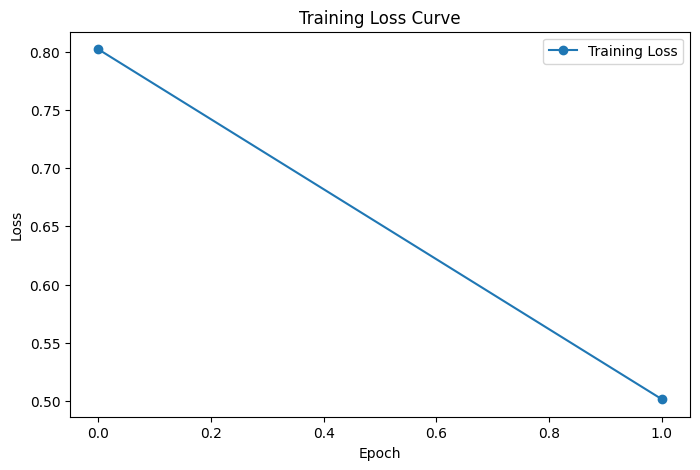

In [33]:
# Import matplotlib for plotting
import matplotlib.pyplot as plt

# Create the loss curve
plt.figure(figsize=(8, 5))

# Plot the training loss
plt.plot(training_losses, marker="o", label="Training Loss")

# Add a title
plt.title("Training Loss Curve")

# Add labels
plt.xlabel("Epoch")
plt.ylabel("Loss")

# Show the legend
plt.legend()

# Display the graph
plt.show()

## Q8 – Evaluate the Model

In [34]:
# Put the model into evaluation mode
model.eval()

# Use a small part of the validation dataset
validation_stories = dataset["validation"].select(range(100))

# Combine validation stories into one text
validation_text = "\n".join(validation_stories["text"])

# Convert validation characters into tokens
validation_tokens = [
    char_to_int[ch]
    for ch in validation_text
    if ch in char_to_int
]

# Create validation sequences
validation_X = []
validation_y = []

for i in range(len(validation_tokens) - sequence_length):

    # Create input sequence
    validation_X.append(
        validation_tokens[i:i + sequence_length]
    )

    # Create target sequence
    validation_y.append(
        validation_tokens[i + 1:i + sequence_length + 1]
    )

# Convert validation data to tensors
validation_X = torch.tensor(
    validation_X,
    dtype=torch.long
)

validation_y = torch.tensor(
    validation_y,
    dtype=torch.long
)

# Use only a small number of validation sequences
validation_X = validation_X[:500]
validation_y = validation_y[:500]

# Move validation data to the selected device
validation_X = validation_X.to(device)
validation_y = validation_y.to(device)

# Disable gradient calculation during evaluation
with torch.no_grad():

    # Make predictions
    validation_output = model(validation_X)

    # Calculate validation loss
    validation_loss = loss_function(
        validation_output.reshape(-1, vocab_size),
        validation_y.reshape(-1)
    )

# Display validation loss
print("Validation Loss:", validation_loss.item())

Validation Loss: 2.152466058731079


In [35]:
# Calculate perplexity from validation loss
perplexity = torch.exp(validation_loss)

# Display perplexity
print("Perplexity:", perplexity.item())

Perplexity: 8.60605525970459


## Q9 – Generate Stories

In [36]:
# Generate new text using the trained Transformer model
def generate_story(prompt, max_length=200):

    # Set the model to evaluation mode
    model.eval()

    # Convert the prompt characters into tokens
    tokens = [
        char_to_int[ch]
        for ch in prompt
        if ch in char_to_int
    ]

    # Convert tokens into a PyTorch tensor
    input_tokens = torch.tensor(
        [tokens],
        dtype=torch.long
    ).to(device)

    # Generate new characters one by one
    with torch.no_grad():

        for _ in range(max_length):

            # Keep only the last sequence_length tokens
            input_context = input_tokens[:, -sequence_length:]

            # Get model predictions
            output = model(input_context)

            # Get predictions for the last token
            last_output = output[:, -1, :]

            # Convert predictions into probabilities
            probabilities = F.softmax(last_output, dim=-1)

            # Select the token with the highest probability
            next_token = torch.argmax(
                probabilities,
                dim=-1
            ).unsqueeze(0)

            # Add the new token to the sequence
            input_tokens = torch.cat(
                [input_tokens, next_token],
                dim=1
            )

    # Convert tokens back into characters
    generated_text = "".join(
        int_to_char[token.item()]
        for token in input_tokens[0]
    )

    return generated_text

In [37]:
# Set the starting prompt
prompt = "Once upon a time"

# Generate a story from the prompt
generated_story = generate_story(
    prompt,
    max_length=200
)

# Display the generated story
print(generated_story)

Once upon a time, there was a little cherry tree was small and weak. The cherry tree was small and weak it a big crab and wanted to be friends. "Hi, I am Fin. Do you want to play?" asked the little girl named Lily to


In [38]:
# Try another starting prompt
prompt = "A little boy"

# Generate a story
generated_story = generate_story(
    prompt,
    max_length=200
)

# Display the generated story
print(generated_story)

A little boy named Tim came to play with them. The cherry tree was small and weak it a big crab and wanted to be friends. "Hi, I am Fin. Do you want to play?" asked the little girl named Lily to go home, Beep kne


## Q10 – Experience with Model Settings

In [39]:
# Try a different number of training epochs
# We use only 1 epoch to keep the experiment fast
epochs_test = 1

# Store the loss from the experiment
experiment_losses = []

# Train the model for the new number of epochs
for epoch in range(epochs_test):

    # Set the model to training mode
    model.train()

    # Reset the total loss
    total_loss = 0

    # Process each batch
    for inputs, targets in train_loader:

        # Move data to the selected device
        inputs = inputs.to(device)
        targets = targets.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Make predictions
        outputs = model(inputs)

        # Calculate the loss
        loss = loss_function(
            outputs.reshape(-1, vocab_size),
            targets.reshape(-1)
        )

        # Calculate gradients
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Add the loss
        total_loss += loss.item()

    # Calculate average loss
    average_loss = total_loss / len(train_loader)

    # Store the experiment loss
    experiment_losses.append(average_loss)

    # Display the result
    print(
        f"Experiment Epoch {epoch + 1}/{epochs_test} - "
        f"Loss: {average_loss:.4f}"
    )

Experiment Epoch 1/1 - Loss: 0.3838


In [40]:
# Display the original training losses
print("Original Training Losses:", training_losses)

# Display the new experiment losses
print("Experiment Losses:", experiment_losses)

Original Training Losses: [0.8019943165171678, 0.5016162568216871]
Experiment Losses: [0.38381303040085324]


In [41]:
# Generate a new story after changing the training setting
prompt = "Once upon a time"

# Generate the story
experiment_story = generate_story(
    prompt,
    max_length=200
)

# Display the generated story
print(experiment_story)

Once upon a time, in a big castle, there was a brown kayak. The crab looked at Fin and said, "No, I don't want to play. I am cold and I don't feel like I will freeze now. Let's play together!" And so, Fin and the cra


### Observation

The number of training epochs affects the model's learning.
More training can reduce the training loss, while fewer epochs
may produce less learned text. The generated story can also
change when the training settings are changed.

## Q11 – Save the Trained Model

In [42]:
# Save the trained model parameters
torch.save(
    model.state_dict(),
    "tiny_transformer_model.pth"
)

# Display a confirmation message
print("Model saved successfully!")

Model saved successfully!


In [43]:
# Create a dictionary containing the model configuration
model_config = {
    "vocab_size": vocab_size,
    "embedding_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "sequence_length": sequence_length
}

# Save the configuration
torch.save(
    model_config,
    "tiny_transformer_config.pth"
)

# Display a confirmation message
print("Model configuration saved successfully!")

Model configuration saved successfully!


In [44]:
# Import os to check saved files
import os

# Check whether the model file exists
print(
    "Model file exists:",
    os.path.exists("tiny_transformer_model.pth")
)

# Check whether the configuration file exists
print(
    "Configuration file exists:",
    os.path.exists("tiny_transformer_config.pth")
)

Model file exists: True
Configuration file exists: True


#Build a Chat Window with Gradio

In [45]:
# Install Gradio for creating the chat interface
!pip install gradio

In [46]:
# Import Gradio
import gradio as gr

In [47]:
# Create a function to generate text from a user prompt
def chat_with_model(prompt):

    # Check whether the user entered a prompt
    if not prompt.strip():
        return "Please enter a prompt."

    # Generate text using the trained Transformer
    response = generate_story(
        prompt,
        max_length=200
    )

    # Return the generated text
    return response

In [48]:
# Create the Gradio interface
demo = gr.Interface(
    fn=chat_with_model,
    inputs=gr.Textbox(
        label="Enter your story prompt",
        placeholder="Once upon a time..."
    ),
    outputs=gr.Textbox(
        label="Generated Story"
    ),
    title="Tiny Transformer Story Generator",
    description="Generate a short story using the trained Transformer model."
)

# Launch the interface
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://48d836420967bc460a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
